# The First Cold Night, Madrid 1920–2025
### Does the first cold night of autumn still come when it used to?

Every autumn in Madrid there is a first night when the temperature drops below 5°C. This notebook finds that night for every autumn since 1920 at the weather station in Retiro park and asks whether it now comes later than it did a century ago, and how much of any change comes from the city around the station.

**Data.** NOAA's Global Historical Climatology Network daily record for Madrid Retiro (station SP000003195), which has the lowest temperature of almost every night since 1920. ERA5, a reanalysis of past weather on a grid of squares roughly 25 kilometers across, from the Open-Meteo historical weather API. AEMET's own daily record for the station, for this autumn. `scripts/download_data.py` downloads all three into `data/raw`.

## 1. Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"

THRESHOLD = 5.0            # a cold night has a minimum below this, in °C
FIRST, LAST = 1920, 2025   # autumns covered
EARLY = (1920, 1949)       # first thirty autumns
RECENT = (1996, 2025)      # last thirty autumns

COLORS = {"station": "#3f6c96", "early": "#a8793a", "recent": "#c06a85", "ink": "#1c1e21", "soft": "#8b8e93", "rule": "#e3e4e1"}
plt.rcParams.update({"font.family": ["Helvetica Neue", "Helvetica", "DejaVu Sans"], "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})

def as_date(day):
    """Days after August 1 as a month and day."""
    return (pd.Timestamp(2001, 8, 1) + pd.Timedelta(days=round(day))).strftime("%B %-d")

def between(df, lo, hi, key="autumn"):
    return df[(df[key] >= lo) & (df[key] <= hi)]

## 2. Load the data

In [2]:
raw = pd.read_csv(RAW / "SP000003195.csv", usecols=["DATE", "TMIN", "TMIN_ATTRIBUTES"], dtype={"TMIN_ATTRIBUTES": str})
raw["DATE"] = pd.to_datetime(raw["DATE"])
flags = raw["TMIN_ATTRIBUTES"].fillna(",,").str.split(",", expand=True)
raw["mflag"], raw["qflag"] = flags[0], flags[1]

print("Downloaded:", json.loads((RAW / "download.json").read_text())["downloaded_utc"])
print("Days in the file:", len(raw), "from", raw["DATE"].min().date(), "to", raw["DATE"].max().date())
raw.tail()

Downloaded: 2026-11-17T11:03:09+00:00
Days in the file: 38994 from 1920-01-01 to 2026-11-06


,DATE,TMIN,TMIN_ATTRIBUTES,mflag,qflag
38989,2026-11-02,78.0,"H,,2",H,
38990,2026-11-03,81.0,"H,,2",H,
38991,2026-11-04,52.0,"H,,2",H,
38992,2026-11-05,65.0,"H,,2",H,
38993,2026-11-06,60.0,"H,,2",H,


GHCN stores temperatures in tenths of a degree, and each value carries three flags: measurement, quality and source.

## 3. Data checks

Before any analysis I want to know three things: how many values failed GHCN's quality checks, how complete the record is, and whether the way the values are measured changed at any point.

In [3]:
failed = (raw["qflag"] != "") & raw["TMIN"].notna()
print("Minimum temperatures that failed a quality check:", int(failed.sum()))

clean = raw[~failed & raw["TMIN"].notna()].copy()
clean["tmin"] = clean["TMIN"] / 10
tmin = clean.set_index("DATE")["tmin"].sort_index()

days = pd.Series(1, index=tmin.index).resample("YE").sum()
coverage = (days / days.index.map(lambda d: 366 if d.is_leap_year else 365)).loc["1920":"2025"]
print(f"Share of days with a minimum, 1920–2025: {len(tmin['1920':'2025']) / len(pd.date_range('1920-01-01', '2025-12-31')):.1%}")
print("Years under 95% complete:", [d.year for d, c in coverage.items() if c < 0.95])

Minimum temperatures that failed a quality check: 14
Share of days with a minimum, 1920–2025: 99.3%
Years under 95% complete: [1936, 1937, 1939, 2025]


In [4]:
print(clean["mflag"].value_counts().rename("measurement flag"))
print()
print("First value with measurement flag H:", clean.loc[clean["mflag"] == "H", "DATE"].min().date())

mflag
     38715
H       38
Name: measurement flag, dtype: int64

First value with measurement flag H: 2026-09-29


The record is close to complete. 1936, 1937 and 1939 have the largest gaps, and most of October to December 2025 is missing.

The measurement flag matters for this autumn. From September 29, 2026, every minimum carries flag "H", which GHCN's documentation defines as the lowest hourly temperature. An hourly reading can miss the true overnight low, so these values run warm. No earlier value carries the flag, so 1920 to 2025 is not affected, but this autumn needs another source (section 10).

## 4. The first cold night of each autumn

An autumn runs from August 1 to July 31. For each one I find the first night below 5°C. If any night is missing before that date, a gap could be hiding an earlier cold night, so I keep the date but mark the autumn as incomplete and leave it out of the averages.

In [5]:
def first_cold_nights(series, threshold=THRESHOLD, years=range(FIRST, LAST + 1)):
    rows = []
    for y in years:
        start = pd.Timestamp(y, 8, 1)
        window = series[start: pd.Timestamp(y + 1, 7, 31)]
        cold = window[window < threshold]
        if cold.empty:
            rows.append({"autumn": y, "valid": False})
            continue
        first = cold.index[0]
        gaps = pd.date_range(start, first).difference(window.index)
        rows.append({
            "autumn": y,
            "date": first.date().isoformat(),
            "day": (first - start).days,
            "tmin_c": float(cold.iloc[0]),
            "missing_before": len(gaps),
            "earliest_possible": (gaps[0] - start).days if len(gaps) else (first - start).days,
            "valid": len(gaps) == 0,
        })
    return pd.DataFrame(rows)

fc = first_cold_nights(tmin)
valid = fc[fc["valid"]]
fc.to_csv(PROCESSED / "first_cold_night.csv", index=False)
print(f"{len(valid)} of {len(fc)} autumns are complete up to their first cold night")
print("Left out:", fc.loc[~fc["valid"], "autumn"].tolist())

100 of 106 autumns are complete up to their first cold night
Left out: [1943, 1949, 2017, 2022, 2024, 2025]


That leaves 100 autumns. The six left out all have missing nights before their first cold night.

## 5. The early and recent decades

In [6]:
early, recent = between(valid, *EARLY)["day"], between(valid, *RECENT)["day"]
summary = pd.DataFrame({
    "autumns": [early.size, recent.size],
    "average first cold night": [as_date(early.mean()), as_date(recent.mean())],
    "median": [as_date(early.median()), as_date(recent.median())],
    "cold by October 31": [f"{(early <= 91).sum()} of {early.size}", f"{(recent <= 91).sum()} of {recent.size}"],
}, index=[f"{EARLY[0]}–{EARLY[1]}", f"{RECENT[0]}–{RECENT[1]}"])
print(f"Shift in the average: {recent.mean() - early.mean():.1f} days")
summary

Shift in the average: 14.6 days


,autumns,average first cold night,median,cold by October 31
1920–1949,28,October 23,October 26,25 of 28
1996–2025,26,November 6,November 7,8 of 26


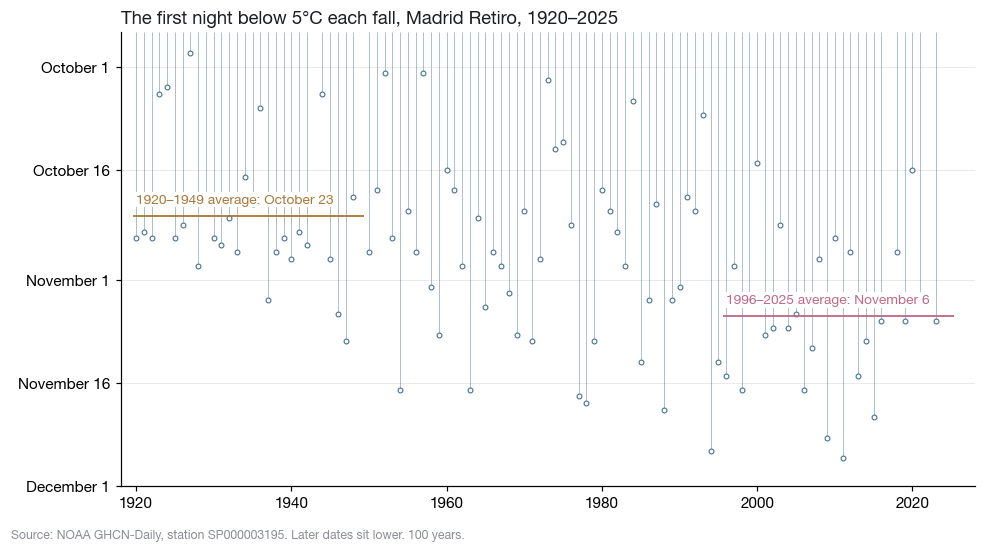

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
top = min(61, valid["day"].min() - 3)   # start above the earliest date (September 29, 1927)
ax.vlines(valid["autumn"], top, valid["day"], color=COLORS["station"], linewidth=0.5, alpha=0.55)
ax.scatter(valid["autumn"], valid["day"], s=10, facecolor="white", edgecolor=COLORS["station"], linewidth=0.7, zorder=3)
for (lo, hi), c in [(EARLY, COLORS["early"]), (RECENT, COLORS["recent"])]:
    m = between(valid, lo, hi)["day"].mean()
    ax.hlines(m, lo - 0.4, hi + 0.4, color=c, linewidth=1.2, zorder=4)
    ax.text(lo, m - 1.5, f"{lo}–{hi} average: {as_date(m)}", color=c, fontsize=9, va="bottom", zorder=5,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.2))
ticks = [61, 76, 92, 107, 122]
ax.set_yticks(ticks, [as_date(t) for t in ticks])
ax.set_ylim(top, max(ticks[-1], valid["day"].max() + 3))
ax.invert_yaxis()
ax.set_xlim(FIRST - 2, LAST + 3)
ax.grid(axis="y", color=COLORS["rule"], linewidth=0.5)
ax.set_title("The first night below 5°C each fall, Madrid Retiro, 1920–2025", loc="left", color=COLORS["ink"])
fig.text(0.01, 0.01, "Source: NOAA GHCN-Daily, station SP000003195. Later dates sit lower. 100 years.", fontsize=8, color=COLORS["soft"])
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(CHARTS / "1-first-cold-night.png", dpi=200, facecolor="white")
plt.show()

In [8]:
print("Earliest:", valid.nsmallest(3, "day")[["autumn", "date"]].values.tolist())
print("Latest:  ", valid.nlargest(3, "day")[["autumn", "date"]].values.tolist())
print("Latest in 1920–1949:  ", between(valid, *EARLY).nlargest(1, "day")[["autumn", "date"]].values.tolist())
print("Earliest in 1996–2025:", between(valid, *RECENT).nsmallest(1, "day")[["autumn", "date"]].values.tolist())

Earliest: [[1927, '1927-09-29'], [1952, '1952-10-02'], [1957, '1957-10-02']]
Latest:   [[2011, '2011-11-27'], [1994, '1994-11-26'], [2009, '2009-11-24']]
Latest in 1920–1949:   [[1947, '1947-11-10']]
Earliest in 1996–2025: [[2000, '2000-10-15']]


The average first cold night moved from October 23 to November 6, about two weeks later. In 25 of the 28 early autumns a night below 5°C had come by the end of October, against 8 of 26 in the recent period.

Single years are messy. The first cold night has come as early as September 29 (1927) and as late as November 27 (2011), and in 1947 it did not come until November 10 while in 2000 it came on October 15. The three latest first cold nights in the whole record all came after 1990.

## 6. Is it a trend?

The dates are skewed and have a few extreme years, so I use the Theil-Sen slope, which is the median of the slopes between every pair of years, and Kendall's tau for the test.

In [9]:
ts = stats.theilslopes(valid["day"], valid["autumn"])
tau = stats.kendalltau(valid["autumn"], valid["day"])
print(f"Theil-Sen slope: {ts.slope * 10:.2f} days a decade (95% interval {ts.low_slope * 10:.2f} to {ts.high_slope * 10:.2f})")
print(f"Kendall's tau: {tau.statistic:.3f}, p = {tau.pvalue:.1e}")

Theil-Sen slope: 1.76 days a decade (95% interval 1.07 to 2.61)
Kendall's tau: 0.296, p = 1.6e-05


The date moved later by about 1.8 days a decade, and ordinary ups and downs from one year to the next are very unlikely to add up to a trend that large.

## 7. Gaps and the 5°C line

Two choices could be driving the result. The first is leaving out incomplete autumns. As a worst case for the finding, I put every incomplete autumn back in at the earliest date its gap allows. The second is the 5°C line itself, so I repeat the comparison at 3°C and 0°C.

In [10]:
with_gaps = fc.dropna(subset=["day"])
worst = between(with_gaps, *RECENT)["earliest_possible"].mean() - between(with_gaps, *EARLY)["earliest_possible"].mean()
print(f"Worst case for the gaps: recent autumns still {worst:.1f} days later")

for threshold in (5.0, 3.0, 0.0):
    f = first_cold_nights(tmin, threshold)
    f = f[f["valid"]]
    shift = between(f, *RECENT)["day"].mean() - between(f, *EARLY)["day"].mean()
    print(f"Shift with a {threshold:g}°C line: {shift:.1f} days")

Worst case for the gaps: recent autumns still 9.6 days later
Shift with a 5°C line: 14.6 days
Shift with a 3°C line: 18.8 days
Shift with a 0°C line: 26.9 days


Even in the worst case the recent autumns come out 9.6 days later, and a colder line makes the shift larger, 18.8 days at 3°C and 26.9 days at 0°C. The 5°C line changes the size of the shift but not its direction.

## 8. November

In [11]:
nov = tmin[tmin.index.month == 11]
g = nov.groupby(nov.index.year)
nc = pd.DataFrame({"days": g.size(), "cold_nights": g.apply(lambda s: int((s < THRESHOLD).sum())), "mean_tmin_c": g.mean().round(2)})
nc.index.name = "year"
nc = nc.loc[FIRST:LAST].reset_index()
nc["complete"] = nc["days"] == 30
nc.to_csv(PROCESSED / "november_cold_nights.csv", index=False)

full = nc[nc["complete"]]
print(f"Novembers with all 30 days: {len(full)}")
pd.DataFrame({
    "nights below 5°C": [between(full, *EARLY, key="year")["cold_nights"].mean(), between(full, *RECENT, key="year")["cold_nights"].mean()],
    "average minimum (°C)": [between(full, *EARLY, key="year")["mean_tmin_c"].mean(), between(full, *RECENT, key="year")["mean_tmin_c"].mean()],
}, index=[f"{EARLY[0]}–{EARLY[1]}", f"{RECENT[0]}–{RECENT[1]}"]).round(1)

Novembers with all 30 days: 99


,nights below 5°C,average minimum (°C)
1920–1949,16.1,4.6
1996–2025,10.0,6.4


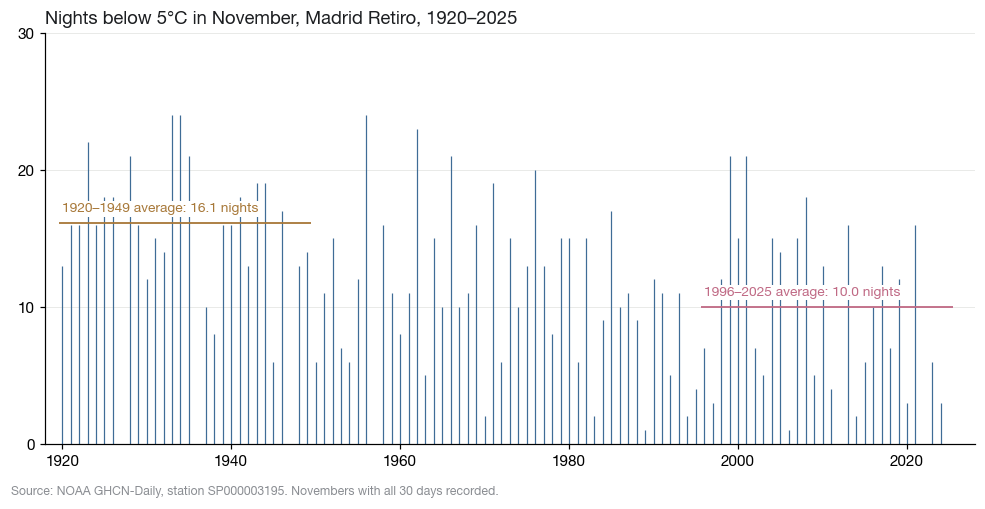

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.vlines(full["year"], 0, full["cold_nights"], color=COLORS["station"], linewidth=0.8)
for (lo, hi), c in [(EARLY, COLORS["early"]), (RECENT, COLORS["recent"])]:
    m = between(full, lo, hi, key="year")["cold_nights"].mean()
    ax.hlines(m, lo - 0.4, hi + 0.4, color=c, linewidth=1.2)
    ax.text(lo, m + 0.6, f"{lo}–{hi} average: {m:.1f} nights", color=c, fontsize=9, va="bottom",
            bbox=dict(facecolor="white", edgecolor="none", pad=1.2))
ax.set_xlim(FIRST - 2, LAST + 3)
ax.set_ylim(0, 30)
ax.set_yticks([0, 10, 20, 30])
ax.grid(axis="y", color=COLORS["rule"], linewidth=0.5)
ax.set_title("Nights below 5°C in November, Madrid Retiro, 1920–2025", loc="left", color=COLORS["ink"])
fig.text(0.01, 0.01, "Source: NOAA GHCN-Daily, station SP000003195. Novembers with all 30 days recorded.", fontsize=8, color=COLORS["soft"])
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(CHARTS / "2-november-cold-nights.png", dpi=200, facecolor="white")
plt.show()

The average November went from 16.1 nights below 5°C to 10.0, and its average nightly minimum from 4.6°C to 6.4°C. The 5°C line sits between the old Madrid and the new one.

## 9. The city or the climate

Retiro is a park in the middle of a city that has grown up around it for a century, and cities keep some of the day's heat through the night. ERA5 rebuilds past weather from observations of every kind on a coarse grid, so it is less tied to the city. ERA5 starts in 1940, so the comparison uses 1940 to 1969 against 1996 to 2025 for both sources.

In [13]:
j = json.loads((RAW / "era5_madrid.json").read_text())
era5 = pd.Series(j["daily"]["temperature_2m_min"], index=pd.to_datetime(j["daily"]["time"]), dtype=float).dropna()
print("ERA5 grid point:", j["latitude"], j["longitude"], "| last day:", era5.index.max().date())

e5 = first_cold_nights(era5, years=range(1940, LAST + 1))
shift = lambda df: between(df, *RECENT)["day"].mean() - between(df, 1940, 1969)["day"].mean()
print(f"ERA5 shift, 1940–1969 to 1996–2025:    {shift(e5[e5['valid']]):.1f} days")
print(f"Station shift, 1940–1969 to 1996–2025: {shift(valid):.1f} days")

ERA5 grid point: 40.5 -3.75 | last day: 2026-11-11
ERA5 shift, 1940–1969 to 1996–2025:    7.9 days
Station shift, 1940–1969 to 1996–2025: 10.0 days


In [14]:
pd.DataFrame({"ERA5": era5["2026-11-01":"2026-11-06"].round(1)})

,ERA5
2026-11-01,5.6
2026-11-02,3.5
2026-11-03,4.4
2026-11-04,2.6
2026-11-05,2.8
2026-11-06,0.9


The wider area moved later as well, by 7.9 days against 10.0 at the station. ERA5's square includes part of the city, so this narrows down the city's share without separating it cleanly.

The gap showed this month. From November 2 to 6, ERA5's preliminary estimate for the square fell below 5°C every night, down to 0.9°C on November 6.

## 10. This autumn

Because NOAA's newest values are hourly lows (section 3), this autumn's figures come from AEMET's daily record for the station.

In [15]:
rows = json.loads((RAW / "aemet_3195_2026.json").read_text())["rows"]
aemet = pd.Series({r["fecha"]: float(r["tmin"].replace(",", ".")) for r in rows if r.get("tmin")}).sort_index()
aemet.index = pd.to_datetime(aemet.index)
aemet = aemet["2026-08-01":]

complete = pd.date_range("2026-08-01", aemet.index.max()).difference(aemet.index).empty
first_2026 = aemet[aemet < THRESHOLD].index[0]
print("Complete from August 1:", complete, "| days:", len(aemet))
print("Coldest night, August to October:", aemet[:"2026-10-31"].min(), "°C")
print("First night below 5°C:", first_2026.date(), "at", aemet[first_2026], "°C")
print("Nights below 5°C, November 2 to 6:", int((aemet["2026-11-02":"2026-11-06"] < THRESHOLD).sum()))

Complete from August 1: True | days: 100
Coldest night, August to October: 7.4 °C
First night below 5°C: 2026-11-04 at 4.7 °C
Nights below 5°C, November 2 to 6: 1


This autumn's first night below 5°C at Retiro was November 4, at 4.7°C, two days before the average of the last thirty years. It was the only night below 5°C from November 2 to 6, while ERA5's square was below 5°C on all five.

## 11. Checking the numbers

The main figures are recomputed here with plain Python, without pandas or the functions above, straight from the raw file. A mistake in one version is unlikely to repeat in the other, and any mismatch stops the notebook with an error.

In [16]:
import csv, statistics
from datetime import date, timedelta

check = {}
with open(RAW / "SP000003195.csv", newline="") as f:
    for row in csv.DictReader(f):
        if row["TMIN"].strip() and not (row["TMIN_ATTRIBUTES"] or ",,").split(",")[1].strip():
            check[date.fromisoformat(row["DATE"])] = int(row["TMIN"]) / 10

def first_day(y, thr=5.0):
    d, gap = date(y, 8, 1), False
    while d <= date(y + 1, 7, 31):
        if d not in check:
            gap = True
        elif check[d] < thr:
            return None if gap else (d - date(y, 8, 1)).days
        d += timedelta(days=1)
    return None

days_by_year = {y: first_day(y) for y in range(FIRST, LAST + 1)}
ok = {y: d for y, d in days_by_year.items() if d is not None}
e = [d for y, d in ok.items() if EARLY[0] <= y <= EARLY[1]]
r = [d for y, d in ok.items() if RECENT[0] <= y <= RECENT[1]]

pairs = [
    ("complete autumns", len(valid), len(ok)),
    ("early average", as_date(early.mean()), as_date(statistics.mean(e))),
    ("recent average", as_date(recent.mean()), as_date(statistics.mean(r))),
    ("shift in days", round(recent.mean() - early.mean(), 1), round(statistics.mean(r) - statistics.mean(e), 1)),
    ("early cold by Oct 31", int((early <= 91).sum()), sum(d <= 91 for d in e)),
    ("recent cold by Oct 31", int((recent <= 91).sum()), sum(d <= 91 for d in r)),
    ("three latest autumns", sorted(valid.nlargest(3, "day")["autumn"]), sorted(sorted(ok, key=ok.get)[-3:])),
]
for name, a, b in pairs:
    assert a == b, f"{name}: {a} vs {b}"
    print(f"{name:22} {str(a):>20}  matches")

complete autumns                        100  matches
early average                    October 23  matches
recent average                   November 6  matches
shift in days                          14.6  matches
early cold by Oct 31                     25  matches
recent cold by Oct 31                     8  matches
three latest autumns     [1994, 2009, 2011]  matches


## 12. Conclusions and limitations

**Conclusions**
- Madrid's first night below 5°C now comes about two weeks later than it did in 1920 to 1949, on November 6 on average instead of October 23.
- The three latest first cold nights in the record all came after 1990, and the date has moved later by about 1.8 days a decade.
- November has fewer cold nights, 10.0 on average against 16.1.
- The wider area moved later too, by 7.9 days against 10.0 at the station, so the shift is not the city alone.
- This autumn's first cold night came on November 4, at 4.7°C, close to the recent average.

**Limitations**
- This is one station in one city.
- ERA5's squares are coarse and include part of Madrid, so they narrow down the city's share without separating it cleanly. Its last few weeks are preliminary.
- The 5°C line is my choice. Other lines change the size of the shift but not its direction.
- NOAA's values from September 29, 2026 are hourly lows, so this autumn relies on AEMET's record instead.